# Retail Sales Forecasting & Price-Driver Analysis
**End-to-end ML pipeline: preprocessing → EDA → feature engineering → regression → hyperparameter tuning → time series forecasting**

**Business question:** A retail chain wants to (1) predict each store's weekly sales, (2) understand what drives sales (holidays, fuel price, CPI, unemployment, seasonality), and (3) forecast chain-wide demand for the next 12 weeks to support inventory and staffing decisions.

**Dataset:** Walmart weekly store sales (45 stores x 143 weeks; columns `Store, Date, Weekly_Sales, Holiday_Flag, Temperature, Fuel_Price, CPI, Unemployment`).
Place `Walmart.csv` next to this notebook to use the real data. If the file is missing, the notebook generates a **synthetic dataset with the same schema** so the whole pipeline still runs.

**Pipeline**
1. Load and clean data
2. Exploratory data analysis
3. Feature engineering (calendar, lag, rolling, cyclical features), leakage-safe
4. Regression modelling with a time-based split
5. Hyperparameter tuning with `TimeSeriesSplit`
6. Model interpretation
7. Chain-level time series forecasting (Holt-Winters vs ARIMA with Fourier terms vs seasonal naive)

In [5]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.stats import randint, uniform, loguniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42
DATA_PATH = Path("Walmart.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Load data

In [9]:
def make_synthetic_walmart(n_stores=45, seed=RANDOM_STATE):
    """Synthetic data with the same schema as the Kaggle Walmart dataset.
    Contains trend, yearly seasonality, holiday effects, AR(1) noise, a few
    missing values and duplicate rows (to exercise the cleaning code)."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2010-02-05", "2012-10-26", freq="7D")
    n, t = len(dates), np.arange(len(dates))
    woy = dates.isocalendar().week.to_numpy().astype(int)
    doy = dates.dayofyear.to_numpy()

    holiday_uplift = {  # flagged holiday weeks
        "2010-02-12": .07, "2011-02-11": .07, "2012-02-10": .07,   # Super Bowl
        "2010-09-10": -.01, "2011-09-09": -.01, "2012-09-07": -.01,  # Labor Day
        "2010-11-26": .27, "2011-11-25": .27,                        # Thanksgiving
        "2010-12-31": -.05, "2011-12-30": -.05,                      # Christmas week
    }
    event = np.zeros(n)
    for d, u in holiday_uplift.items():
        event[dates == pd.Timestamp(d)] = u
    event[woy == 51] += 0.30   # pre-Christmas rush (NOT flagged as a holiday)
    event[woy == 50] += 0.12
    hol_flag = dates.isin(pd.to_datetime(list(holiday_uplift))).astype(int)

    fuel = 2.7 + 0.0075 * t + rng.normal(0, 0.05, n).cumsum() * 0.15
    season = 1 + 0.05 * np.cos(2 * np.pi * (woy - 51) / 52)

    frames = []
    for s in range(1, n_stores + 1):
        base = np.clip(rng.lognormal(np.log(950_000), 0.45), 250_000, 2_200_000)
        temp = 58 + 22 * np.sin(2 * np.pi * (doy - 110) / 365) + rng.normal(0, 8) + rng.normal(0, 4, n)
        cpi = rng.uniform(126, 220) + 0.06 * t + rng.normal(0, 0.2, n).cumsum() * 0.1
        unemp = np.clip(rng.uniform(5, 13) - 0.012 * t + rng.normal(0, 0.1, n).cumsum() * 0.1, 3, 15)
        e = np.zeros(n)
        for i in range(1, n):
            e[i] = 0.5 * e[i - 1] + rng.normal(0, 0.045)
        sales = (base * (1 + 0.0003 * t) * (season + event)
                 * (1 - 0.04 * (fuel - 3)) * (1 - 0.008 * (unemp - 8))
                 * (1 - 0.0015 * (temp - 60)) * np.exp(e))
        frames.append(pd.DataFrame({
            "Store": s, "Date": dates, "Weekly_Sales": sales.round(2), "Holiday_Flag": hol_flag,
            "Temperature": temp.round(2), "Fuel_Price": fuel.round(3),
            "CPI": cpi.round(3), "Unemployment": unemp.round(3)}))
    out = pd.concat(frames, ignore_index=True)
    out.loc[rng.choice(len(out), 40, replace=False), "Temperature"] = np.nan   # missing values
    out = pd.concat([out, out.sample(8, random_state=seed)], ignore_index=True)  # duplicates
    out["Date"] = out["Date"].dt.strftime("%d-%m-%Y")                            # same format as Kaggle file
    return out

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH); USING_SYNTHETIC = False
    print(f"Loaded real dataset: {DATA_PATH}")
else:
    df = make_synthetic_walmart(); USING_SYNTHETIC = True
    print("Walmart.csv not found -> using SYNTHETIC data with the same schema.")
print(df.shape)
df.head()

Loaded real dataset: Walmart.csv
(6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,"1,643,690.90",0,42.31,2.57,211.10,8.11
1,1,12-02-2010,"1,641,957.44",1,38.51,2.55,211.24,8.11
2,1,19-02-2010,"1,611,968.17",0,39.93,2.51,211.29,8.11
3,1,26-02-2010,"1,409,727.59",0,46.63,2.56,211.32,8.11
4,1,05-03-2010,"1,554,806.68",0,46.50,2.62,211.35,8.11


## 2. Preprocessing

In [3]:
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate (Store, Date) rows:", df.duplicated(subset=["Store", "Date"]).sum())

df = (df.drop_duplicates(subset=["Store", "Date"])
        .sort_values(["Store", "Date"]).reset_index(drop=True))

# time-aware imputation: interpolate inside each store's own series
num_cols = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]
df[num_cols] = df.groupby("Store")[num_cols].transform(lambda s: s.interpolate(limit_direction="both"))
df["Holiday_Flag"] = df["Holiday_Flag"].astype(int)

# sanity checks
assert df["Weekly_Sales"].gt(0).all(), "non-positive sales found"
assert df.isna().sum().sum() == 0
weeks_per_store = df.groupby("Store")["Date"].nunique()
print(f"\nStores: {df.Store.nunique()} | weeks per store: {weeks_per_store.min()}-{weeks_per_store.max()}")

# outliers: flag with IQR per store, but KEEP them (holiday spikes are real signal)
q1 = df.groupby("Store")["Weekly_Sales"].transform(lambda s: s.quantile(.25))
q3 = df.groupby("Store")["Weekly_Sales"].transform(lambda s: s.quantile(.75))
iqr = q3 - q1
df["is_outlier"] = ((df.Weekly_Sales > q3 + 1.5 * iqr) | (df.Weekly_Sales < q1 - 1.5 * iqr)).astype(int)
print(f"IQR-flagged outliers: {df.is_outlier.sum()} ({df.is_outlier.mean():.1%}) - kept, they are mostly holiday peaks")
print("Share of outliers that fall in the Nov-Dec peak:",
      f"{df.loc[df.is_outlier==1,'Date'].dt.month.isin([11,12]).mean():.0%}")
df.describe().T

Missing values per column:
 Store            0
Date             0
Weekly_Sales     0
Holiday_Flag     0
Temperature     40
Fuel_Price       0
CPI              0
Unemployment     0
dtype: int64 

Duplicate (Store, Date) rows: 8

Stores: 45 | weeks per store: 143-143
IQR-flagged outliers: 225 (3.5%) - kept, they are mostly holiday peaks
Share of outliers that fall in the Nov-Dec peak: 89%


,count,mean,min,25%,50%,75%,max,std
Store,"6,435.00",23.00,1.00,12.00,23.00,34.00,45.00,12.99
Date,6435,2011-06-17 00:00:00,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,"6,435.00","1,056,503.43","299,835.71","695,498.21","989,812.06","1,349,200.55","3,266,581.00","466,759.82"
Holiday_Flag,"6,435.00",0.07,0.00,0.00,0.00,0.00,1.00,0.26
Temperature,"6,435.00",61.43,16.01,46.94,62.43,75.40,107.87,17.64
Fuel_Price,"6,435.00",3.22,2.70,2.98,3.25,3.46,3.72,0.29
CPI,"6,435.00",183.57,126.21,161.06,187.57,207.71,226.22,27.28
Unemployment,"6,435.00",7.93,3.27,5.79,8.09,10.08,12.73,2.42
is_outlier,"6,435.00",0.03,0.00,0.00,0.00,0.00,1.00,0.18


## 3. Exploratory data analysis

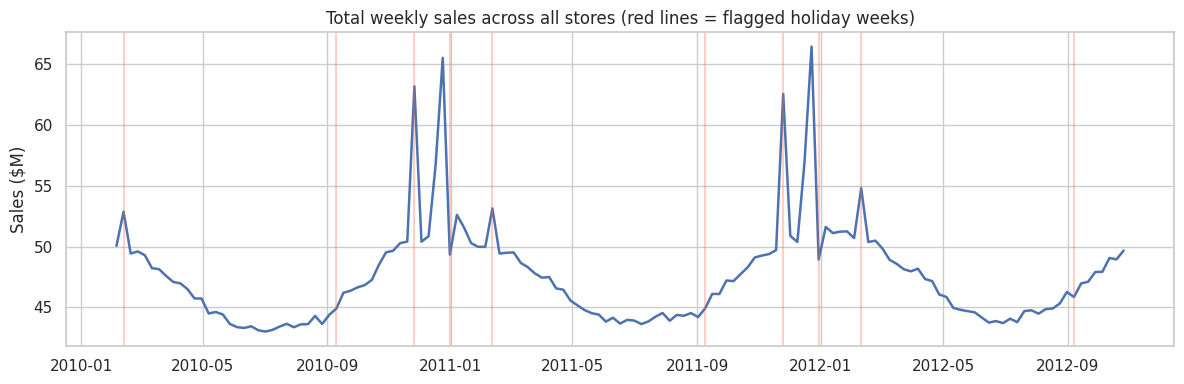

Flagged holiday weeks sell +10.3% vs normal weeks on average

Top-5 weeks by average store sales:


,avg_store_sales,holiday_flag
Date,,
2011-12-23,"1,476,347.48",0
2010-12-24,"1,455,757.97",0
2010-11-26,"1,403,814.14",1
2011-11-25,"1,389,947.25",1
2011-12-16,"1,264,614.40",0


In [4]:
total = df.groupby("Date")["Weekly_Sales"].sum() / 1e6
hol_dates = df.loc[df.Holiday_Flag == 1, "Date"].unique()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(total.index, total.values, lw=1.8)
for d in hol_dates:
    ax.axvline(d, color="tomato", alpha=.3)
ax.set(title="Total weekly sales across all stores (red lines = flagged holiday weeks)", ylabel="Sales ($M)")
savefig("01_total_weekly_sales")

uplift = df.groupby("Holiday_Flag")["Weekly_Sales"].mean()
print(f"Flagged holiday weeks sell {uplift[1] / uplift[0] - 1:+.1%} vs normal weeks on average")
peak = df.groupby("Date").agg(avg_store_sales=("Weekly_Sales", "mean"), holiday_flag=("Holiday_Flag", "max")).nlargest(5, "avg_store_sales")
print("\nTop-5 weeks by average store sales:"); display(peak)

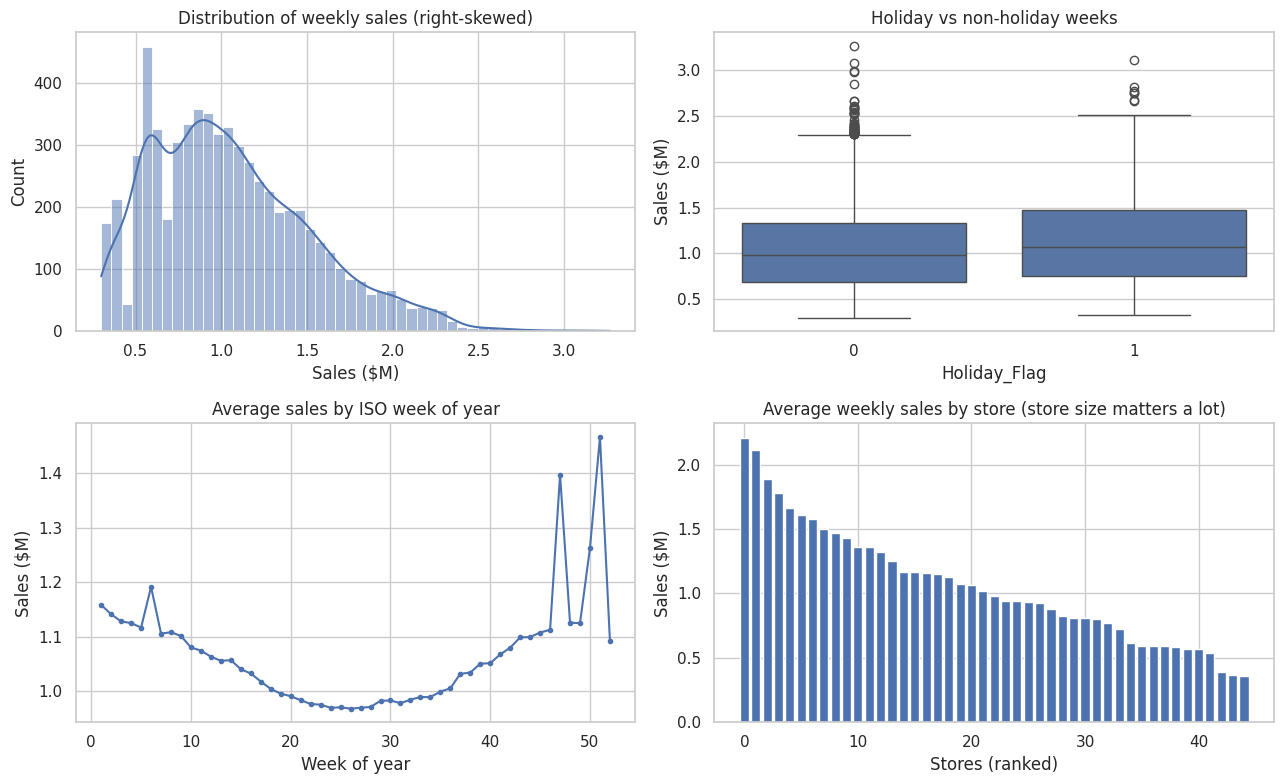

In [5]:
df["week_of_year"] = df["Date"].dt.isocalendar().week.astype(int)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

sns.histplot(df["Weekly_Sales"] / 1e6, bins=50, kde=True, ax=axes[0, 0])
axes[0, 0].set(title="Distribution of weekly sales (right-skewed)", xlabel="Sales ($M)")

sns.boxplot(data=df, x="Holiday_Flag", y=df["Weekly_Sales"] / 1e6, ax=axes[0, 1])
axes[0, 1].set(title="Holiday vs non-holiday weeks", ylabel="Sales ($M)")

woy_mean = df.groupby("week_of_year")["Weekly_Sales"].mean() / 1e6
axes[1, 0].plot(woy_mean.index, woy_mean.values, marker="o", ms=3)
axes[1, 0].set(title="Average sales by ISO week of year", xlabel="Week of year", ylabel="Sales ($M)")

store_mean = df.groupby("Store")["Weekly_Sales"].mean().sort_values(ascending=False) / 1e6
axes[1, 1].bar(range(len(store_mean)), store_mean.values)
axes[1, 1].set(title="Average weekly sales by store (store size matters a lot)", xlabel="Stores (ranked)", ylabel="Sales ($M)")
savefig("02_eda_panels")

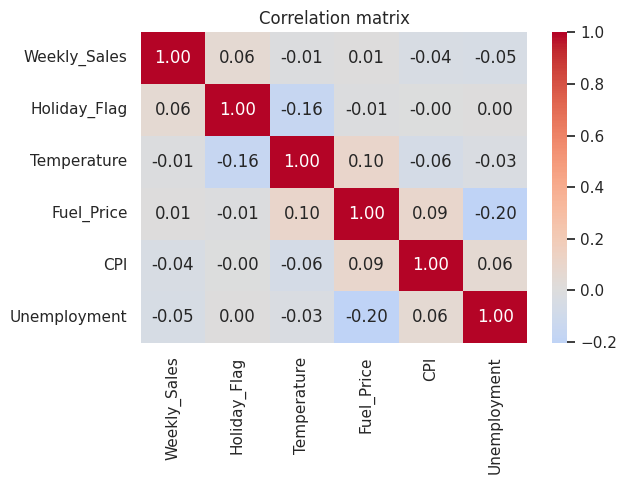

Note: raw correlations with sales are weak because store size dominates the variance;
the lag/store features below capture that baseline level.


In [6]:
corr_cols = ["Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
savefig("03_correlation")
print("Note: raw correlations with sales are weak because store size dominates the variance;")
print("the lag/store features below capture that baseline level.")

## 4. Feature engineering
All lag and rolling features are computed **per store** and shifted so that a row only uses information available *before* that week (no leakage).
The task is therefore **one-week-ahead** forecasting per store.

In [7]:
def build_features(d):
    d = d.sort_values(["Store", "Date"]).copy()
    d["month"] = d.Date.dt.month
    d["quarter"] = d.Date.dt.quarter
    d["week_of_year"] = d.Date.dt.isocalendar().week.astype(int)
    d["woy_sin"] = np.sin(2 * np.pi * d.week_of_year / 52)   # cyclical encoding of the season
    d["woy_cos"] = np.cos(2 * np.pi * d.week_of_year / 52)

    g = d.groupby("Store")["Weekly_Sales"]
    for lag in (1, 2, 4, 52):
        d[f"lag_{lag}"] = g.shift(lag)
    d["roll_mean_4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())
    d["roll_std_4"] = g.transform(lambda s: s.shift(1).rolling(4).std())
    d["fuel_change"] = d.groupby("Store")["Fuel_Price"].diff()
    d["Store"] = d["Store"].astype(str)
    return d

feat = build_features(df)
NUM_FEATS = ["Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment", "month", "quarter",
             "week_of_year", "woy_sin", "woy_cos", "lag_1", "lag_2", "lag_4", "lag_52",
             "roll_mean_4", "roll_std_4", "fuel_change"]
CAT_FEATS = ["Store"]
TARGET = "Weekly_Sales"

model_df = feat.dropna(subset=NUM_FEATS).sort_values(["Date", "Store"]).reset_index(drop=True)
print(f"Rows before/after dropping warm-up weeks (lag_52): {len(feat)} -> {len(model_df)}")
print(f"Engineered features: {len(NUM_FEATS) + len(CAT_FEATS)}")

# time-based split: last 20 weeks are the test set
TEST_WEEKS = 20
cutoff = model_df["Date"].drop_duplicates().sort_values().iloc[-TEST_WEEKS]
train = model_df[model_df.Date < cutoff]; test = model_df[model_df.Date >= cutoff]
X_train, y_train = train[NUM_FEATS + CAT_FEATS], train[TARGET]
X_test, y_test = test[NUM_FEATS + CAT_FEATS], test[TARGET]
print(f"Train: {train.Date.min().date()} -> {train.Date.max().date()} ({len(train)} rows)")
print(f"Test : {test.Date.min().date()} -> {test.Date.max().date()} ({len(test)} rows)")

Rows before/after dropping warm-up weeks (lag_52): 6435 -> 4095
Engineered features: 18
Train: 2011-02-04 -> 2012-06-08 (3195 rows)
Test : 2012-06-15 -> 2012-10-26 (900 rows)


## 5. Regression modelling (baselines vs ML models)

In [8]:
def evaluate(y_true, y_pred, name):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {"model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAPE_%": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
            "R2": r2_score(y_true, y_pred)}

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS)])

def make_pipe(est):
    return Pipeline([("prep", preprocess), ("model", est)])

results = [evaluate(y_test, test["lag_1"], "Baseline: last week (naive)"),
           evaluate(y_test, test["lag_52"], "Baseline: same week last year")]

models = {
    "Linear Regression": make_pipe(LinearRegression()),
    "Ridge": make_pipe(Ridge(alpha=10)),
    "Random Forest (default)": make_pipe(RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting (default)": make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}
fitted = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train); fitted[name] = pipe
    results.append(evaluate(y_test, pipe.predict(X_test), name))

res_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
res_df

,model,MAE,RMSE,MAPE_%,R2
0,Baseline: last week (naive),"43,838.04","60,284.07",4.27,0.98
1,Random Forest (default),"44,892.20","62,466.49",4.34,0.98
2,Linear Regression,"46,202.97","64,084.61",4.50,0.98
3,Ridge,"46,156.93","64,175.13",4.48,0.98
4,Gradient Boosting (default),"46,004.74","64,774.82",4.43,0.98
5,Baseline: same week last year,"62,923.25","88,003.45",5.99,0.96


## 6. Hyperparameter tuning
`RandomizedSearchCV` with **`TimeSeriesSplit`** so every validation fold lies *after* its training fold. The test set is not touched during tuning.

In [9]:
tscv = TimeSeriesSplit(n_splits=4)
search_spaces = {
    "Random Forest (tuned)": (
        make_pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
        {"model__n_estimators": randint(150, 500), "model__max_depth": randint(5, 30),
         "model__min_samples_leaf": randint(1, 10), "model__max_features": uniform(0.3, 0.7)}),
    "Gradient Boosting (tuned)": (
        make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
        {"model__learning_rate": loguniform(0.02, 0.3), "model__max_depth": randint(3, 10),
         "model__max_iter": randint(150, 600), "model__min_samples_leaf": randint(10, 60),
         "model__l2_regularization": loguniform(1e-3, 10)}),
}

searches = {}
for name, (pipe, space) in search_spaces.items():
    s = RandomizedSearchCV(pipe, space, n_iter=20, cv=tscv, scoring="neg_root_mean_squared_error",
                           random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    s.fit(X_train, y_train); searches[name] = s
    print(f"{name}: CV RMSE = {-s.best_score_:,.0f}")
    print("   best params:", {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})
    results.append(evaluate(y_test, s.predict(X_test), name))

res_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
res_df

Random Forest (tuned): CV RMSE = 80,935
   best params: {'max_depth': 25, 'max_features': np.float64(0.4092), 'min_samples_leaf': 3, 'n_estimators': 364}


Gradient Boosting (tuned): CV RMSE = 83,129
   best params: {'l2_regularization': np.float64(0.0267), 'learning_rate': np.float64(0.0428), 'max_depth': 6, 'max_iter': 190, 'min_samples_leaf': 38}


,model,MAE,RMSE,MAPE_%,R2
0,Baseline: last week (naive),"43,838.04","60,284.07",4.27,0.98
1,Random Forest (tuned),"43,593.58","60,975.91",4.18,0.98
2,Gradient Boosting (tuned),"44,248.87","62,129.01",4.26,0.98
3,Random Forest (default),"44,892.20","62,466.49",4.34,0.98
4,Linear Regression,"46,202.97","64,084.61",4.50,0.98
5,Ridge,"46,156.93","64,175.13",4.48,0.98
6,Gradient Boosting (default),"46,004.74","64,774.82",4.43,0.98
7,Baseline: same week last year,"62,923.25","88,003.45",5.99,0.96


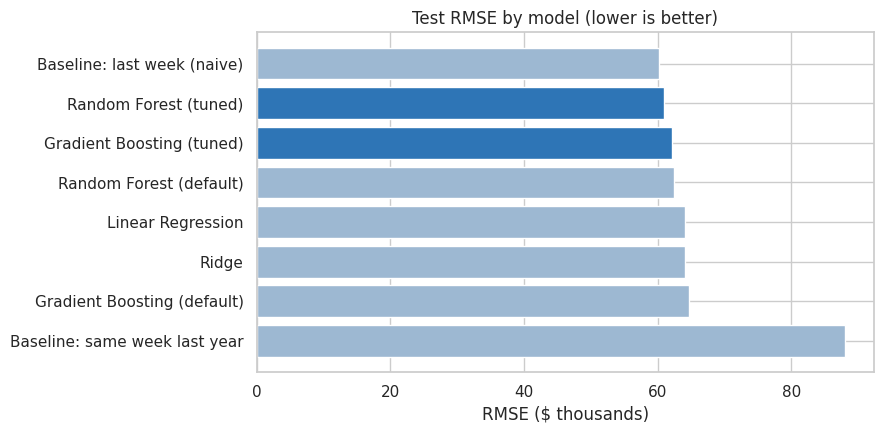

Final model (selected on CV): Random Forest (tuned)


,model,MAE,RMSE,MAPE_%,R2,RMSE_vs_naive_%
0,Baseline: last week (naive),"43,838.04","60,284.07",4.27,0.98,0.00
1,Random Forest (tuned),"43,593.58","60,975.91",4.18,0.98,1.15
2,Gradient Boosting (tuned),"44,248.87","62,129.01",4.26,0.98,3.06
3,Random Forest (default),"44,892.20","62,466.49",4.34,0.98,3.62
4,Linear Regression,"46,202.97","64,084.61",4.50,0.98,6.30
5,Ridge,"46,156.93","64,175.13",4.48,0.98,6.45
6,Gradient Boosting (default),"46,004.74","64,774.82",4.43,0.98,7.45
7,Baseline: same week last year,"62,923.25","88,003.45",5.99,0.96,45.98


In [10]:
base_rmse = res_df.loc[res_df.model == "Baseline: last week (naive)", "RMSE"].iloc[0]
res_df["RMSE_vs_naive_%"] = (res_df["RMSE"] / base_rmse - 1) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
order = res_df.sort_values("RMSE", ascending=False)
ax.barh(order["model"], order["RMSE"] / 1e3, color=["#2E75B6" if "tuned" in m else "#9DB8D2" for m in order["model"]])
ax.set(title="Test RMSE by model (lower is better)", xlabel="RMSE ($ thousands)")
savefig("04_model_comparison")

# choose the final model by cross-validated RMSE (not by test score), then report test once
best_name = min(searches, key=lambda k: -searches[k].best_score_)
best_model = searches[best_name].best_estimator_
print(f"Final model (selected on CV): {best_name}")
res_df

## 7. Model diagnostics and interpretation

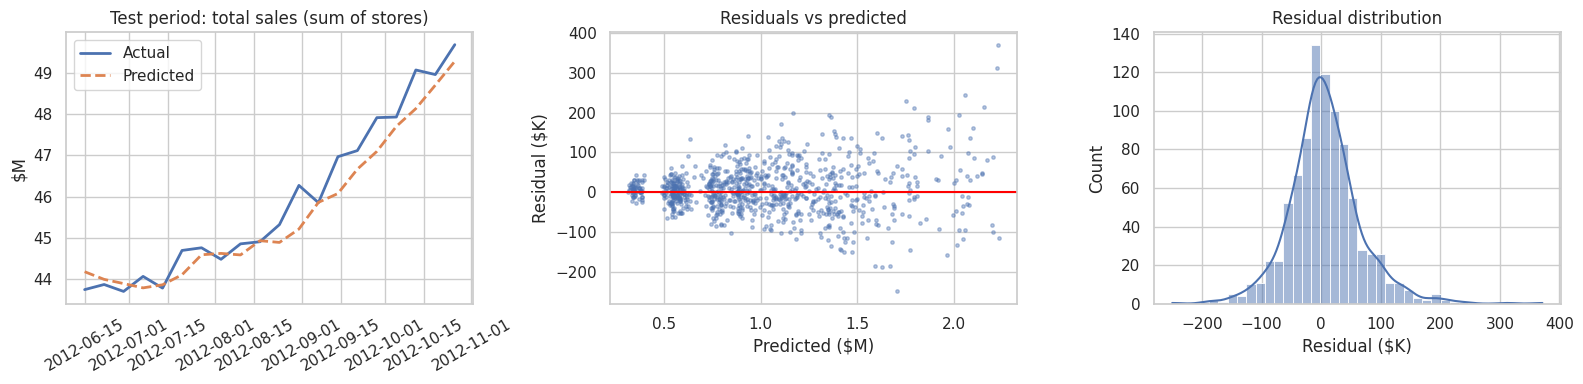

In [11]:
test_pred = test[["Date", "Store", TARGET]].copy()
test_pred["pred"] = best_model.predict(X_test)
test_pred["resid"] = test_pred[TARGET] - test_pred["pred"]

agg = test_pred.groupby("Date")[[TARGET, "pred"]].sum() / 1e6
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(agg.index, agg[TARGET], label="Actual", lw=2); axes[0].plot(agg.index, agg["pred"], "--", label="Predicted", lw=2)
axes[0].set(title="Test period: total sales (sum of stores)", ylabel="$M"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
axes[1].scatter(test_pred["pred"] / 1e6, test_pred["resid"] / 1e3, s=6, alpha=.4); axes[1].axhline(0, color="red")
axes[1].set(title="Residuals vs predicted", xlabel="Predicted ($M)", ylabel="Residual ($K)")
sns.histplot(test_pred["resid"] / 1e3, bins=40, kde=True, ax=axes[2]); axes[2].set(title="Residual distribution", xlabel="Residual ($K)")
savefig("05_diagnostics")

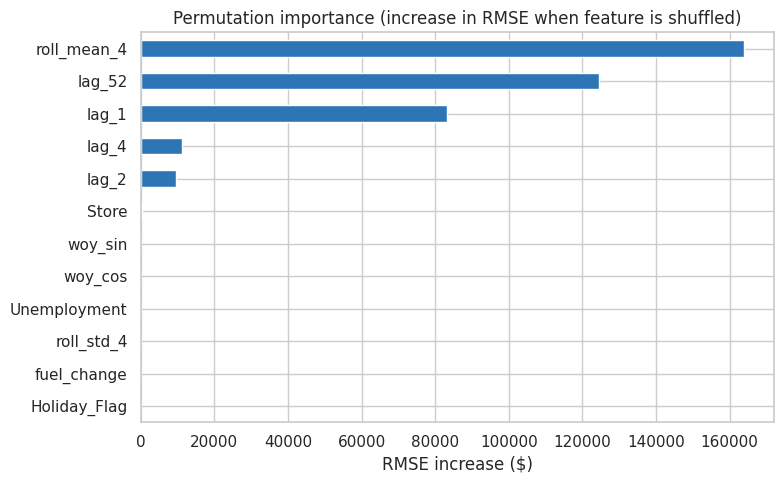

roll_mean_4   163,874.00
lag_52        124,584.00
lag_1          83,178.00
lag_4          11,059.00
lag_2           9,559.00
Store             444.00
woy_sin           113.00
woy_cos            87.00
dtype: float64


In [12]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
imp.head(12)[::-1].plot.barh(ax=ax, color="#2E75B6")
ax.set(title="Permutation importance (increase in RMSE when feature is shuffled)", xlabel="RMSE increase ($)")
savefig("06_feature_importance")
print(imp.head(8).round(0))

## 8. Chain-level time series forecasting
For planning, the business needs **total weekly sales** for the coming quarter. We aggregate across stores and compare three approaches on a 16-week hold-out:
- **Seasonal naive**: same week last year (benchmark any model must beat)
- **Holt-Winters** (additive trend + seasonality, period 52)
- **ARIMA with Fourier terms**: dynamic harmonic regression, a robust way to model 52-week seasonality

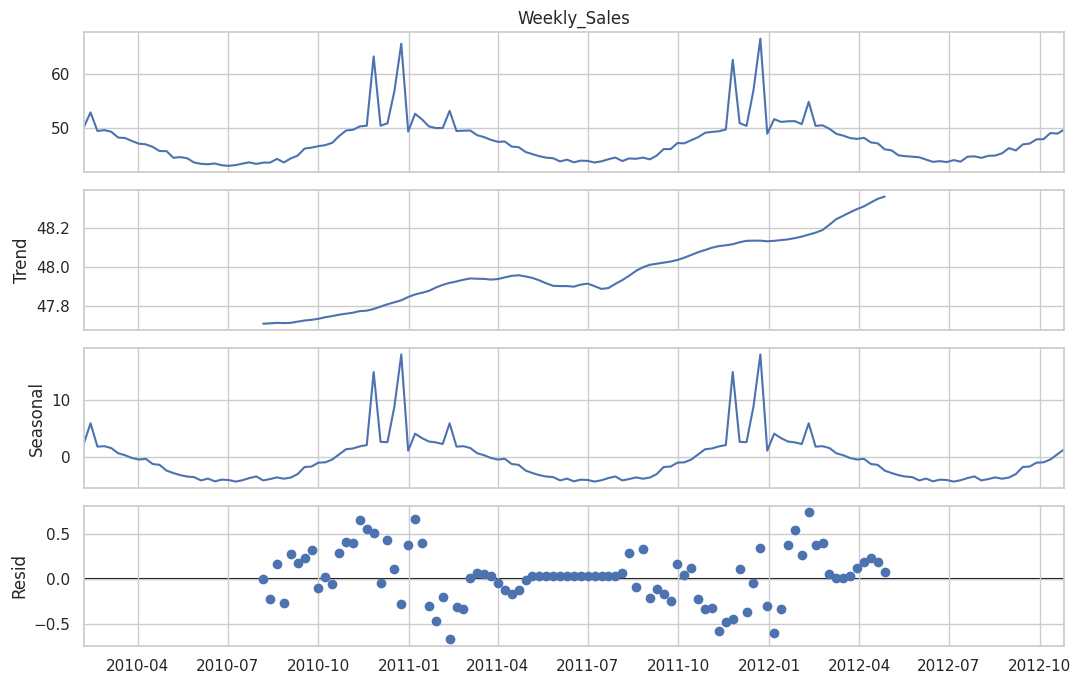

ADF test - Original series: statistic = -2.89, p-value = 0.0462 -> stationary
ADF test - First difference: statistic = -6.68, p-value = 0.0000 -> stationary


In [13]:
ts = df.groupby("Date")["Weekly_Sales"].sum().asfreq("W-FRI")
assert ts.isna().sum() == 0

dec = seasonal_decompose(ts / 1e6, model="additive", period=52)
fig = dec.plot(); fig.set_size_inches(11, 7)
savefig("07_decomposition")

for label, series in [("Original series", ts), ("First difference", ts.diff().dropna())]:
    stat, p = adfuller(series)[:2]
    print(f"ADF test - {label}: statistic = {stat:.2f}, p-value = {p:.4f} -> {'stationary' if p < 0.05 else 'non-stationary'}")

In [14]:
def fourier_terms(pos, K=3, period=52):
    pos = np.asarray(pos); cols = []
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * pos / period), np.cos(2 * np.pi * k * pos / period)]
    return np.column_stack(cols)

def fc_snaive(train, h):
    return np.array([train.iloc[len(train) - 52 + (i % 52)] for i in range(h)]), None

def fc_holt_winters(train, h):
    m = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add",
                             seasonal_periods=52, initialization_method="estimated").fit()
    return m.forecast(h).to_numpy(), None

def fc_arima_fourier(train, h):
    n = len(train)
    m = ARIMA(train.to_numpy(), exog=fourier_terms(np.arange(n)), order=(1, 1, 1)).fit()
    res = m.get_forecast(h, exog=fourier_terms(np.arange(n, n + h)))
    return np.asarray(res.predicted_mean), np.asarray(res.conf_int(alpha=0.2))   # 80% interval

ts_models = {"Seasonal naive": fc_snaive, "Holt-Winters": fc_holt_winters, "ARIMA + Fourier": fc_arima_fourier}

H = 16
train_ts, test_ts = ts.iloc[:-H], ts.iloc[-H:]
ts_results, ts_preds = [], {}
for name, fn in ts_models.items():
    pred, _ = fn(train_ts, H); ts_preds[name] = pred
    ts_results.append(evaluate(test_ts, pred, name))
ts_res_df = pd.DataFrame(ts_results).sort_values("RMSE").reset_index(drop=True)
ts_res_df

,model,MAE,RMSE,MAPE_%,R2
0,Holt-Winters,"515,112.54","645,608.76",1.11,0.87
1,ARIMA + Fourier,"678,411.73","851,974.49",1.45,0.78
2,Seasonal naive,"752,920.17","875,141.39",1.61,0.76


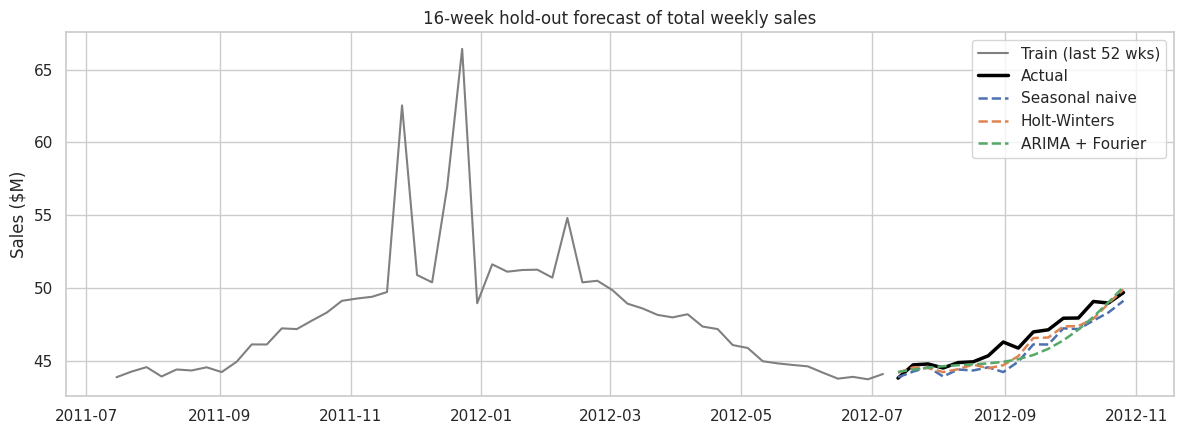

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(train_ts.index[-52:], train_ts.iloc[-52:] / 1e6, color="gray", label="Train (last 52 wks)")
ax.plot(test_ts.index, test_ts / 1e6, color="black", lw=2.5, label="Actual")
for name, pred in ts_preds.items():
    ax.plot(test_ts.index, pred / 1e6, "--", lw=1.8, label=name)
ax.set(title=f"{H}-week hold-out forecast of total weekly sales", ylabel="Sales ($M)"); ax.legend()
savefig("08_ts_holdout")

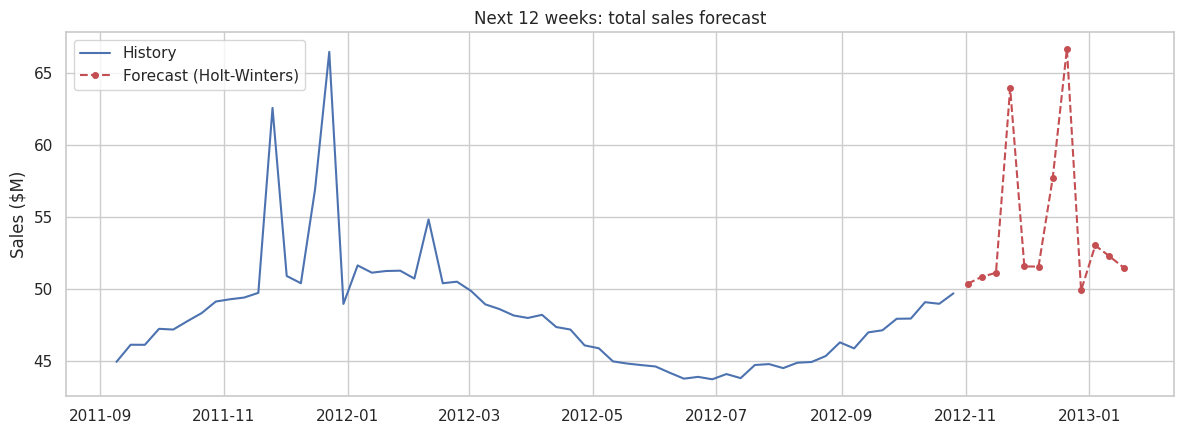

,forecast,forecast_M
2012-11-02,"50,336,958.66",50.34
2012-11-09,"50,823,342.51",50.82
2012-11-16,"51,099,758.27",51.10
2012-11-23,"63,918,017.25",63.92
2012-11-30,"51,541,253.79",51.54
2012-12-07,"51,533,246.38",51.53
2012-12-14,"57,674,588.89",57.67
2012-12-21,"66,647,125.28",66.65
2012-12-28,"49,878,878.16",49.88
2013-01-04,"52,997,659.49",53.00


In [16]:
# refit the best time series model on ALL data and forecast the next 12 weeks
best_ts = ts_res_df.loc[0, "model"]; FUTURE = 12
mean_fc, ci = ts_models[best_ts](ts, FUTURE)
future_idx = pd.date_range(ts.index[-1] + pd.Timedelta(days=7), periods=FUTURE, freq="W-FRI")
forecast = pd.Series(mean_fc, index=future_idx, name="forecast")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ts.index[-60:], ts.iloc[-60:] / 1e6, label="History")
ax.plot(forecast.index, forecast / 1e6, "r--o", ms=4, label=f"Forecast ({best_ts})")
if ci is not None:
    ax.fill_between(future_idx, ci[:, 0] / 1e6, ci[:, 1] / 1e6, color="red", alpha=.15, label="80% interval")
ax.set(title=f"Next {FUTURE} weeks: total sales forecast", ylabel="Sales ($M)"); ax.legend()
savefig("09_ts_future_forecast")
forecast.to_frame().assign(forecast_M=lambda d: d.forecast / 1e6)

## 9. Save artefacts and summary

In [17]:
joblib.dump(best_model, MODEL_DIR / "best_regression_model.joblib")
res_df.to_csv("regression_results.csv", index=False)
ts_res_df.to_csv("timeseries_results.csv", index=False)
forecast.to_csv("forecast_next_12_weeks.csv")

best_row = res_df[res_df.model == best_name].iloc[0]
ts_base = ts_res_df.loc[ts_res_df.model == "Seasonal naive", "RMSE"].iloc[0]
print("=" * 70)
print("PROJECT SUMMARY" + ("  (SYNTHETIC DATA - rerun on the real Walmart.csv before quoting numbers)" if USING_SYNTHETIC else ""))
print("=" * 70)
print(f"Rows modelled           : {len(model_df):,} store-weeks, {model_df.Store.nunique()} stores")
print(f"Engineered features     : {len(NUM_FEATS) + len(CAT_FEATS)}")
print(f"Best regression model   : {best_name}")
print(f"  Test MAPE             : {best_row['MAPE_%']:.2f}%   R2: {best_row['R2']:.3f}")
naive_row = res_df[res_df.model == "Baseline: last week (naive)"].iloc[0]
print(f"  RMSE vs naive baseline: {best_row['RMSE_vs_naive_%']:+.1f}%  (negative = better than naive)")
print(f"  MAE  vs naive baseline: {(best_row['MAE'] / naive_row['MAE'] - 1) * 100:+.1f}%")
print(f"  Beats the naive baseline on RMSE? {'YES' if best_row['RMSE'] < naive_row['RMSE'] else 'NO - report this honestly; see limitations'}")
print(f"Best time series model  : {best_ts}")
print(f"  RMSE vs seasonal naive: {(ts_res_df.loc[0, 'RMSE'] / ts_base - 1) * 100:+.1f}%   MAPE: {ts_res_df.loc[0, 'MAPE_%']:.2f}%")
print(f"Top drivers             : {', '.join(imp.index[:4])}")

PROJECT SUMMARY  (SYNTHETIC DATA - rerun on the real Walmart.csv before quoting numbers)
Rows modelled           : 4,095 store-weeks, 45 stores
Engineered features     : 18
Best regression model   : Random Forest (tuned)
  Test MAPE             : 4.18%   R2: 0.981
  RMSE vs naive baseline: +1.1%  (negative = better than naive)
  MAE  vs naive baseline: -0.6%
  Beats the naive baseline on RMSE? NO - report this honestly; see limitations
Best time series model  : Holt-Winters
  RMSE vs seasonal naive: -26.2%   MAPE: 1.11%
Top drivers             : roll_mean_4, lag_52, lag_1, lag_4


## 10. Limitations and next steps
- **Naive baseline is strong:** weekly sales are highly autocorrelated, and the 20-week test window contains no Nov-Dec peak, so 'same as last week' is hard to beat. Compare models on holiday and peak weeks separately (rolling-origin backtest over Nov-Dec) to show where ML adds value.\n- **Forecast horizon:** the store-level model is one-week-ahead because it uses lag features; multi-step forecasts need recursive or direct strategies.
- **Missing drivers:** promotions, markdowns, store attributes and product-level prices are not in this dataset; adding them is the most valuable improvement.
- **Hierarchical forecasting:** reconcile store-level and chain-level forecasts so they add up.
- **Productionisation:** track experiments with MLflow, serve the model via FastAPI or Azure ML, monitor drift, and retrain on a schedule.